In [2]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal,Annotated
import operator
from langchain_core.messages import SystemMessage,HumanMessage,BaseMessage #we will be using LLM for every node so for that we need to set prompt
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI


KeyboardInterrupt: 

In [ ]:
from langgraph.checkpoint.memory import MemorySaver  #used to store messages in side lang graph. It will only be erased when we will reload the kernel

In [ ]:
load_dotenv()

True

In [ ]:
llm=ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=1.0
)

In [ ]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]  #base message is like chat history [user prompt +response]

In [ ]:
def chat_node(state:ChatState):
    response=llm.invoke(state['messages']) #semd to LLM
    return {'messages':[response]}


In [ ]:
#add checkpoin to save the messages
checkpoint=MemorySaver()

graph=StateGraph(ChatState)

#add nodes
graph.add_node('chat_node',chat_node)

#add edges 
graph.add_edge(START,'chat_node')

#add edges 
graph.add_edge('chat_node',END)

#execute graph
chatbot=graph.compile(checkpointer=checkpoint)

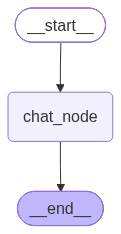

In [ ]:
chatbot

In [ ]:
initial_state={
    'messages':[HumanMessage(content='What is Object Oriented Programming?')]
}

In [ ]:
response=chatbot.invoke(initial_state, config={"configurable": {"thread_id": "1"}})

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


In [ ]:
response['messages'][-1].content

[{'type': 'text',
  'text': '**Object-Oriented Programming (OOP)** is a computer programming model that organizes software design'},
 {'type': 'text',
  'text': ' around **data**, or **objects**, rather than functions and logic. \n\nAn object can be loosely defined as a field that has unique attributes and behavior. \n\nTo understand OOP, it helps to compare it to the traditional way of programming (Procedural Programming):\n* **Procedural Programming** is like a list of instructions: *Step A, do this; Step B, do that.* (Function-driven).\n* **Object-Oriented Programming** is like a collection of interacting real-world things (objects). Each object has its own data and its own rules for how it interacts with the world.\n\n---\n\n### The Four Pillars of OOP\nOOP rests on four core concepts (often called the "four pillars"):\n\n#### 1. Encapsulation\n* **What it is:** Bundling the data (variables) and methods (functions) that operate on that data into a single unit (an object), and restr

In [ ]:
#making a loop so that user can keep on chatting

using thread we can make different chat sections 

In [ ]:
thread_id="1"   #make different chats like thread 1 is of x topic thread 2 is of y topic

while True:
    user_message=input("type here...")
    print('user: ',user_message)

    if user_message.strip().lower() in ['exit','quit','bye']:
        break

    else: 
        config={'configurable':{'thread_id':thread_id}}  
        response=chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
        print('AI:',response['messages'][-1].content)

user:  ji


c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


AI: [{'type': 'text', 'text': 'Hello! How can I help you today?', 'extras': {'signature': 'EmAKXgFpFH0T4fyq9FixtLP+3J45VcLEt7Mfs5yYR0eOZ6nuvXZ3KKFj7rcFjax/x8U5O/emSp4vdDKBgsvwbkBbJhBMfAtb1hkXONqfDii9bC51MtKy1gIoYhGpScc1apA='}}]
user:  


c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3945: UserWarning: HumanMessage with empty content was removed to prevent API error
  warnings.warn(


ValueError: Model 'gemini-3.5-flash-lite' does not support model prefilling. The final request turn must be a user message or a function response.

In [ ]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='What is Object Oriented Programming?', additional_kwargs={}, response_metadata={}, id='4303c532-7984-4590-bc16-dc1e08a996a0'), AIMessage(content=[{'type': 'text', 'text': '**Object-Oriented Programming (OOP)** is a computer programming model that organizes software design'}, {'type': 'text', 'text': ' around **data**, or **objects**, rather than functions and logic. \n\nAn object can be loosely defined as a field that has unique attributes and behavior. \n\nTo understand OOP, it helps to compare it to the traditional way of programming (Procedural Programming):\n* **Procedural Programming** is like a list of instructions: *Step A, do this; Step B, do that.* (Function-driven).\n* **Object-Oriented Programming** is like a collection of interacting real-world things (objects). Each object has its own data and its own rules for how it interacts with the world.\n\n---\n\n### The Four Pillars of OOP\nOOP rests on four core concepts (of

Streaming Responses in LangGraph

Generating output token by token instead of all together

In [ ]:
config={'configurable':{'thread_id':'thread-1'}}

In [ ]:
res=chatbot.invoke({'messages':[HumanMessage(content="Generate a blog about Capital of India?")]},config=config)
print(res['messages'][-1].content)

c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': "**Title: Beyond the Monuments: Discovering the Soul of New Delhi, India’s Vibrant Capital**\n\nWhen you think of India, what comes to mind? Is it the Taj Mahal (which, by the way, is a few hours away in Agra), the spices of a bustling street market, or the colorful festivals? While India is a vast tapestry of diverse cultures, at its heart lies a city that stitches it all together: **New Delhi**, the capital of India.\n\nDelhi is not just a city; it is a time machine. It is a place where ancient history rubs shoulders with hyper-modern skyscrapers, where a 17th-century mosque looks out over a metro station, and where the aroma of street food competes with the honking of auto-rickshaws. \n\nIf you are planning a trip or simply want to understand the heartbeat of this incredible nation, welcome to your ultimate guide to India’s capital.\n\n---\n\n### A Tale of Seven Cities\nDelhi’s history reads like an epic fantasy novel. Over the millennia, empires rose and f

using streaming 

In [ ]:
response=chatbot.stream(
    {'messages':[HumanMessage(content="Generate a blog about Capital of India?")]},
    config=config,
    stream_mode='messages'
)

In [ ]:
print(response)

<generator object Pregel.stream at 0x000002D20EE6B9D0>


In [ ]:

from langchain_core.messages import HumanMessage

for message_chunk, metadata in chatbot.stream(
    {
        "messages": [
            HumanMessage(content="Generate a blog about the Capital of India")
        ]
    },
    config=config,
    stream_mode="messages"
):
    if message_chunk.content:
        print(message_chunk.content, end="", flush=True)


c:\Users\Dell\Desktop\Generative AI\LangGraph\.conda\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[{'type': 'text', 'text': '**Title', 'index': 0}][{'type': 'text', 'text': ': More Than Just Concrete and Crowds: Unveiling the Soul of New Delhi', 'index': 0}][{'type': 'text', 'text': '**\n\nLet’s play a quick word-association game. When I say "India," what pops into your head', 'index': 0}][{'type': 'text', 'text': '? \n\nMaybe it’s the ethereal white marble of the Taj Mahal, the vibrant hues of a Holi festival, or the serene back', 'index': 0}][{'type': 'text', 'text': 'waters of Kerala. But behind the postcards lies the beating heart of the nation—a sprawling, chaotic, magnificent metropolis that', 'index': 0}][{'type': 'text', 'text': ' orchestrates the rhythm of the entire country. \n\nWelcome to **New Delhi**, the capital of India.\n\nOften', 'index': 0}][{'type': 'text', 'text': ' misunderstood as just a pit stop for international travelers rushing off to Agra or Jaipur, Delhi is a destination in its own right. It is a', 'index': 0}][{'type': 'text', 'text': ' city of seven gh

building permanent chat memory

using DB (SQLLite)

In [ ]:
# # from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

# from langgraph.checkpoint.sqlite import SqliteSaver


In [ ]:
from langsmith import traceable
# from langgraph.checkpoint.sqlite import SqliteSaver
load_dotenv()

## If you have openAI API key and want to use OpenAI models, uncomment the line below and comment the Gemini LLM initialization

# llm = ChatOpenAI()

## if you want to use Gemini LLM 
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.7
)


class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]


@traceable
def chat_node(state: ChatState):
    #take user query from state
    messages = state['messages']
    # send to llm
    response = llm.invoke(messages)
    # response store state
    return {'messages': [response]}


conn = sqlite3.connect(database="chatbot.db", check_same_thread=False) #chatbot.db will be created
# checkpoint = SqliteSaver(conn) #using sql lite it will be stored in chatbot.db file and not in ram

graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node)

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)


chatbot = graph.compile(checkpointer=checkpoint)


def get_all_threads():
    all_threads = set()
    for ckpt in checkpoint.list(None):
        all_threads.add(ckpt.config['configurable']['thread_id'])

    return list(all_threads)



TOOLS DEMO

In [ ]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph.message import add_messages
from dotenv import load_dotenv

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing import Any
import requests
import math
import os

ADDING TOOLS INSIDE AGENT

In [ ]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.7
)

In [ ]:
search_tool=TavilySearch(
    max_results=5,
    topic="general",
    search_depth="advanced"
)

In [ ]:
print("heje")

heje


In [ ]:
@tool 
def calculator(expression:str)->str:
    """
    Useful for simple math calculations.
    Input should be a valid math expression.
    Example: 2 + 2, math.sqrt(16), 10 * 5
    """

    try:
        allowed = {
            "math": math,
            "abs": abs,
            "round": round,
            "min": min,
            "max": max,
            "sum": sum
        }

        result = eval(expression, {"__builtins__": {}}, allowed)
        return str(result)

    except Exception as e:
        return f"Calculation error: {str(e)}"


In [ ]:

@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=MCOIJBGPI78M4OS8"
    r = requests.get(url)
    return r.json()

In [ ]:

@tool
def get_current_weather(location: str) -> str:
    """
    Get the current real-time weather for a given city or location.

    Args:
        location: City or location name, for example:
                  "Dhaka", "London, UK", or "New York, US".

    Returns:
        A formatted current weather report.
    """

    api_key = os.getenv("OPENWEATHER_API_KEY")

    if not api_key:
        return (
            "Weather API key is missing. "
            "Set the OPENWEATHER_API_KEY environment variable."
        )

    try:
        # Step 1: Convert the location name into latitude and longitude
        geocoding_url = "https://api.openweathermap.org/geo/1.0/direct"

        geocoding_params = {
            "q": location,
            "limit": 1,
            "appid": api_key,
        }

        geo_response = requests.get(
            geocoding_url,
            params=geocoding_params,
            timeout=10,
        )
        geo_response.raise_for_status()

        locations: list[dict[str, Any]] = geo_response.json()

        if not locations:
            return f"Could not find the location: {location}"

        latitude = locations[0]["lat"]
        longitude = locations[0]["lon"]
        resolved_name = locations[0].get("name", location)
        country = locations[0].get("country", "")
        state = locations[0].get("state", "")

        # Step 2: Get current weather using latitude and longitude
        weather_url = "https://api.openweathermap.org/data/2.5/weather"

        weather_params = {
            "lat": latitude,
            "lon": longitude,
            "appid": api_key,
            "units": "metric",
        }

        weather_response = requests.get(
            weather_url,
            params=weather_params,
            timeout=10,
        )
        weather_response.raise_for_status()

        weather_data = weather_response.json()

        temperature = weather_data["main"]["temp"]
        feels_like = weather_data["main"]["feels_like"]
        humidity = weather_data["main"]["humidity"]
        pressure = weather_data["main"]["pressure"]
        description = weather_data["weather"][0]["description"]
        wind_speed = weather_data.get("wind", {}).get("speed", "N/A")
        visibility_meters = weather_data.get("visibility")

        visibility_km = (
            round(visibility_meters / 1000, 1)
            if visibility_meters is not None
            else "N/A"
        )

        location_parts = [resolved_name]

        if state:
            location_parts.append(state)

        if country:
            location_parts.append(country)

        display_location = ", ".join(location_parts)

        return (
            f"Current weather in {display_location}:\n"
            f"- Condition: {description.title()}\n"
            f"- Temperature: {temperature}°C\n"
            f"- Feels like: {feels_like}°C\n"
            f"- Humidity: {humidity}%\n"
            f"- Pressure: {pressure} hPa\n"
            f"- Wind speed: {wind_speed} m/s\n"
            f"- Visibility: {visibility_km} km"
        )

    except requests.Timeout:
        return "The weather service request timed out. Please try again."

    except requests.HTTPError as error:
        status_code = error.response.status_code if error.response else "unknown"

        if status_code == 401:
            return "The OpenWeather API key is invalid or inactive."

        return f"Weather API returned an HTTP error: {status_code}"

    except requests.RequestException as error:
        return f"Could not connect to the weather service: {error}"

    except (KeyError, TypeError, ValueError) as error:
        return f"Unexpected weather API response: {error}"

In [ ]:
#make a tool list
tools=[get_stock_price,search_tool,get_current_weather]

llm_with_tools=llm.bind_tools(tools)

In [ ]:
# state
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [ ]:
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

In [ ]:

# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)

In [ ]:
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")     #done so that o/p comes structured

In [ ]:
chatbot = graph.compile()

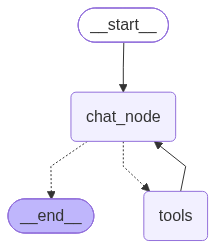

In [ ]:
chatbot

In [ ]:
# Regular chat
out = chatbot.invoke({"messages": [HumanMessage(content="Hello!")]})

print(out["messages"][-1].content)

[{'type': 'text', 'text': 'Hello! How can I help you today?', 'extras': {'signature': 'EqEBCp4BAWkUfROX+ECyzC581WFERLZgSnXsWPYiIPcbNqvJEE8zQlrRgWsiQtDP8EhvZeV97TnqCUOR10r20RpgCY7VlHPLsUqaWmx4eRokpCZmlXYvjyWgrbgCCebCEAIivZucKYo8IM8FPDiVuXBhdKelsO9LFRNNXQiJhfK6CDYUobp/BBWH2OcbRTpxTcdTh75LVsRIglf40YCvIO8BMIE='}}]


In [ ]:

# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is 8989898*90909090+5404040?")]})
print(out["messages"][-1].content)

In [ ]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="what is the new movie releases in 2026")]})
print(out["messages"][-1].content[0])

NameError: name 'chatbot' is not defined

In [ ]:
print(out["messages"][-1].content[0]['text'])

In [ ]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="First find out the stock price of Apple using get stock price tool then use the calculator tool to find out how much will it take to purchase 50 shares?")]})
print(out["messages"][-1].content)

In [ ]:
print(out["messages"][-1].content[0]['text'])


In [ ]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is the current weather in New York?")]})
print(out["messages"][-1].content)

implementing RAG

In [3]:
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

C:\Users\Dell\AppData\Local\Temp\ipykernel_25400\1860997399.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [4]:
load_dotenv()


True

In [5]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.7
)


In [6]:
from pypdf import PdfReader

loader = PyPDFLoader("paper.pdf")


In [7]:
docs = loader.load()


In [8]:
docs

[Document(metadata={'producer': 'Adobe PDF Library 17.0; modified using iText® 5.5.13.4 ©2000-2024 iText Group NV (SPRINGER SBM; licensed version)', 'creator': 'Adobe InDesign 18.3 (Windows)', 'creationdate': '2025-08-20T22:20:53+02:00', 'crossmarkdomains[1]': 'springer.com', 'crossmarkdomains[2]': 'springerlink.com', 'crossmarkdomainexclusive': 'true', 'crossmarkmajorversiondate': '2010-04-23', 'moddate': '2025-08-20T23:51:01+02:00', 'trapped': '/False', 'doi': '10.1038/s41598-025-07104-4', 'source': 'paper.pdf', 'total_pages': 16, 'page': 0, 'page_label': '1'}, page_content='A study on the effectiveness of \nmachine learning models for \nhepatitis prediction\nPopy Khatun1, Shafeel Umam2, Rubaiya Binte Razzak2, Iffat Binta Shamsuddin1 & \nNahid Salma 1\uf02a\nHepatitis continues to be a major global health challenge, leading to high morbidity and mortality \nrates. Despite advances in diagnosis and treatment, early prediction of hepatitis outcomes remains an \nessential area for impro

In [9]:
len(docs)


16

In [10]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)


In [11]:
len(chunks)


96

In [12]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001"
)
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

In [13]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})


In [14]:
ans = retriever.invoke("What are key factors for hepatits?")
ans


[Document(id='3d294d22-f034-4382-af17-12632cda1126', metadata={'producer': 'Adobe PDF Library 17.0; modified using iText® 5.5.13.4 ©2000-2024 iText Group NV (SPRINGER SBM; licensed version)', 'creator': 'Adobe InDesign 18.3 (Windows)', 'creationdate': '2025-08-20T22:20:53+02:00', 'crossmarkdomains[1]': 'springer.com', 'crossmarkdomains[2]': 'springerlink.com', 'crossmarkdomainexclusive': 'true', 'crossmarkmajorversiondate': '2010-04-23', 'moddate': '2025-08-20T23:51:01+02:00', 'trapped': '/False', 'doi': '10.1038/s41598-025-07104-4', 'source': 'paper.pdf', 'total_pages': 16, 'page': 7, 'page_label': '8'}, page_content='several variables that are crucial in understanding the progression and severity of hepatitis, especially in cases \nthat advance to liver cirrhosis. Among the most important features are Ascites, Varices, Bilirubin, Age, Spiders, \nand Alkaline phosphatase, all of which received high importance scores (above 0.85). These features are well-\nestablished markers of liver 

make a tool

In [15]:
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions
    that may be answered using the stored PDF documents.

    Args:
        query: The question or search query used to retrieve PDF content.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)

In [16]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [17]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [18]:

# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

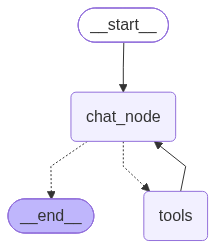

In [19]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")  
chatbot = graph.compile()

chatbot

In [20]:

# Regular chat
#result = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})

#print(result["messages"][-1].content)

In [21]:
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain about ML Algorithms useful for hepatitis prediction in a concise way")]})

print(result["messages"][-1].content)


ReadError: [WinError 10053] An established connection was aborted by the software in your host machine

In [22]:
print(result["messages"][-1].content[0]["text"])


NameError: name 'result' is not defined

HITL

we use interrupt function. it stops execution untill we give decision(yes/no)

persistence is imp in HITL as it needs to execute from the point where it stopped

HITL DEMO IF YES SHOW ANSWER ELSE NO ANSWER SHOWN

In [23]:
from typing import Annotated

from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import AnyMessage, AIMessage

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage

In [24]:
load_dotenv()


True

In [39]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.7
)

In [40]:

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [41]:
def chat_node(state: ChatState):

    #used to pause execution
    decision = interrupt({
        "type": "approval",
        "reason": "Model is about to answer a user question.",
        "question": state["messages"][-1].content,
        "instruction": "Approve this question? yes/no"
    })
    
    if decision["approved"] == 'no':
        return {"messages": [AIMessage(content="Not approved.")]}

    else:
        response = llm.invoke(state["messages"])
        return {"messages": [response]}

In [42]:
# 3. Build the graph: START -> chat -> END
builder = StateGraph(ChatState)

builder.add_node("chat", chat_node)

builder.add_edge(START, "chat")
builder.add_edge("chat", END)

# Checkpointer is required for interrupts
checkpointer = MemorySaver()

# Compile the app
app = builder.compile(checkpointer=checkpointer)

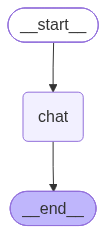

In [43]:
app

In [44]:
# Create a new thread id for this conversation
config = {"configurable": {"thread_id": '1234'}}

# ---- STEP 1: user asks a question ----
initial_input = {
    "messages": [
        ("user", "Explain gradient descent in very simple terms.")
    ]
}

# Invoke the graph for the first time
result = app.invoke(initial_input, config=config)

In [45]:
result

{'messages': [HumanMessage(content='Explain gradient descent in very simple terms.', additional_kwargs={}, response_metadata={}, id='ac61c9de-6f19-418f-a1e1-d54d1667a195')],
 '__interrupt__': [Interrupt(value={'type': 'approval', 'reason': 'Model is about to answer a user question.', 'question': 'Explain gradient descent in very simple terms.', 'instruction': 'Approve this question? yes/no'}, id='825cc6fe1c193ab48f0b205fef3028e7', response_schema=None)]}

In [46]:
message = result['__interrupt__'][0].value
message

{'type': 'approval',
 'reason': 'Model is about to answer a user question.',
 'question': 'Explain gradient descent in very simple terms.',
 'instruction': 'Approve this question? yes/no'}

interrupt aaya hai koi output nhi aaya

In [47]:
user_input = input(f"\nBackend message - {message} \n Approve this question? (y/n): ")


In [ ]:

# Resume the graph with the approval decision
final_result = app.invoke(
    Command(resume={"approved": user_input}), #if yes mila this will resume
    config=config,
)

In [49]:
final_result

{'messages': [HumanMessage(content='Explain gradient descent in very simple terms.', additional_kwargs={}, response_metadata={}, id='ac61c9de-6f19-418f-a1e1-d54d1667a195'),
  AIMessage(content=[{'type': 'text', 'text': 'Imagine you are standing at the top of a foggy mountain, and your goal is to get to the absolute bottom (the valley). \n\nBecause of the thick fog, **you can’t see the bottom**. You can only see the ground right around your feet.\n\nHow do you get to the bottom?\n\n1. You feel the slope of the ground with your foot.\n2. You figure out which direction goes **downwards** the steepest.\n3. You take a step in that direction.\n4. You repeat this process over and over until the ground under your feet feels completely flat. \n\nCongratulations! You’ve reached the bottom. \n\nThat entire process is **Gradient Descent**.\n\n---\n\n### How Computers Use It\n\nIn Artificial Intelligence (AI) and Machine Learning, computers are trying to solve problems by making guesses. \n\n* **Th

add HITL in tools not in node